In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

datos = pd.read_csv("/content/dataset_segmentacion_clientes.csv")

datos.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522


In [2]:
datos.shape

(700, 7)

In [3]:
datos.info()

datos.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   purchase_freq_month   700 non-null    float64
 1   avg_basket_usd        700 non-null    float64
 2   time_on_site_min      700 non-null    float64
 3   discount_sensitivity  700 non-null    float64
 4   returns_rate          700 non-null    float64
 5   noise_gauss           700 non-null    float64
 6   noise_uniform         700 non-null    float64
dtypes: float64(7)
memory usage: 38.4 KB


,0
purchase_freq_month,0
avg_basket_usd,0
time_on_site_min,0
discount_sensitivity,0
returns_rate,0
noise_gauss,0
noise_uniform,0


In [4]:
variables = [
    "purchase_freq_month",
    "avg_basket_usd",
    "time_on_site_min",
    "discount_sensitivity",
    "returns_rate"
]

X = datos[variables]

X.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
0,11.152508,181.300834,33.564036,1.000000,0.800000
1,12.053451,178.637272,35.432081,0.784974,0.000000
2,2.203006,450.185298,7.030757,0.898297,0.000000
3,4.233314,89.006342,10.834453,0.000000,0.800000
4,1.716799,449.773982,7.254548,0.000000,0.003279


In [5]:
escalador = StandardScaler()

X_escalado = escalador.fit_transform(X)

X_escalado

array([[ 1.18104766, -0.43201153,  1.3002238 ,  1.33342344,  1.29867122],
       [ 1.38269638, -0.4492187 ,  1.44497872,  0.83470573, -0.9461957 ],
       [-0.82202607,  1.30503906, -0.75584112,  1.09754027, -0.9461957 ],
       ...,
       [-0.45202644,  1.29540873, -0.73756682, -0.98590965,  1.29867122],
       [ 1.27632981, -0.44336324,  1.45048539,  1.33342344, -0.50162332],
       [ 1.34838143, -0.43390428,  1.4601441 ,  0.30132851,  0.20277751]])

In [6]:
X_escalado_df = pd.DataFrame(
    X_escalado,
    columns=variables
)

X_escalado_df.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
0,1.181048,-0.432012,1.300224,1.333423,1.298671
1,1.382696,-0.449219,1.444979,0.834706,-0.946196
2,-0.822026,1.305039,-0.755841,1.097540,-0.946196
3,-0.367604,-1.028253,-0.461093,-0.985910,1.298671
4,-0.930849,1.302382,-0.738500,-0.985910,-0.936996


In [7]:
inercias = []
valores_k = range(2, 7)

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(X_escalado)
    inercias.append(modelo.inertia_)

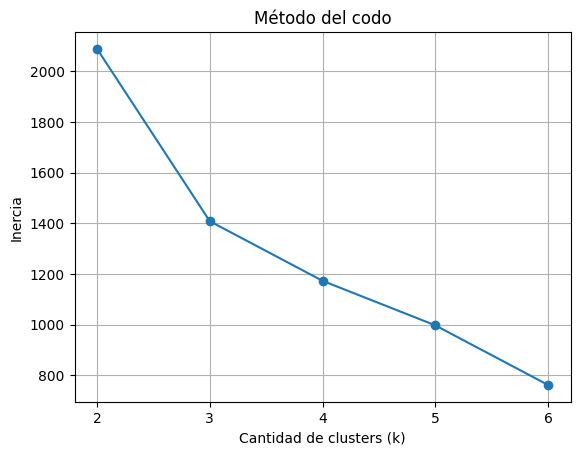

In [8]:
plt.plot(valores_k, inercias, marker="o")

plt.xlabel("Cantidad de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo")

plt.xticks(valores_k)
plt.grid()

plt.show()

En el gráfico podemos observar una disminución pronunciada de la inercia entre k=2 y k=3. A partir de k=3, la reducción comienza a ser más gradual. Por este motivo, se seleccionan 3 clusters como una cantidad razonable para segmentar a los clientes.

In [9]:
modelo_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = modelo_final.fit_predict(X_escalado)

In [10]:
datos["cluster"] = clusters

datos.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform,cluster
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905,0
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460,0
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173,1
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026,2
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522,1


In [11]:
datos["cluster"].value_counts().sort_index()

,count
cluster,
0,230
1,250
2,220


In [12]:
centroides = datos.groupby("cluster")[variables].mean()

centroides.round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
cluster,,,,,
0,11.96,180.00,35.02,0.54,0.33
1,1.85,450.12,5.97,0.36,0.38
2,4.09,89.96,10.00,0.38,0.30


**CLUSTERS:**

Cluster 0: clientes frecuentes y activos
Este grupo es el segmento con mayor frecuencia de compra, mayor tiempo de navegación y mayor sensibilidad a los descuentos. Podrían utilizarse promociones y beneficios para mantener su frecuencia de compra.

Cluster 1: compradores esporádicos de ticket alto valor
Estos clientes compran menos de dos veces por mes, pero tienen un ticket promedio aproximado de 450. Permanecen poco tiempo en el sitio y también presentan la tasa de devoluciones más elevada, por lo cual sería importante analizar las causas de las mismas.

Cluster 2: clientes de ticket bajo valor
Este grupo realiza aproximadamente cuatro compras mensuales y tiene el ticket promedio de valor más bajo. También son bajos sus tiempos de permanencia en el sitio, la sensibilidad a descuentos y la tasa de devoluciones también son relativamente bajos.

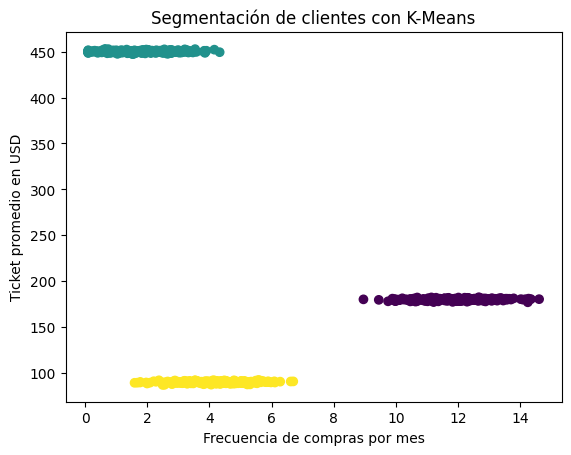

In [13]:
plt.scatter(
    datos["purchase_freq_month"],
    datos["avg_basket_usd"],
    c=datos["cluster"]
)

plt.xlabel("Frecuencia de compras por mes")
plt.ylabel("Ticket promedio en USD")
plt.title("Segmentación de clientes con K-Means")

plt.show()